# Financial Fraud Intelligence
## Intelligent Credit Card Fraud Detection System

**A Data Mining Project for ECE Paris - Bachelor 3 Intelligence Artificielle**

---

### Project Overview

This project implements a complete credit card fraud detection system using Machine Learning techniques. The goal is to identify fraudulent transactions while minimizing false alarms.

**Team:** 3 Students  
**Course:** Data Mining  
**Institution:** ECE Paris

---

# Méthodologie CRISP-DM

Ce projet suit la méthodologie **CRISP-DM** (Cross-Industry Standard Process for Data Mining), qui est le standard de l'industrie pour les projets de Data Mining. Elle se compose de six phases itératives :

1. **Business Understanding** : Compréhension des objectifs métier et des besoins du projet
2. **Data Understanding** : Exploration et analyse des données disponibles
3. **Data Preparation** : Nettoyage, transformation et préparation des données
4. **Modeling** : Construction et entraînement des modèles de Machine Learning
5. **Evaluation** : Évaluation des performances et comparaison des modèles
6. **Deployment** : Mise en production et suivi du modèle

Chaque phase sera documentée avec des explications théoriques, des justifications techniques et des interprétations métier.

---

# Introduction Générale

## Contexte de la fraude financière

La fraude bancaire constitue un enjeu majeur pour les institutions financières à l'échelle mondiale. Avec l'essor des paiements électroniques et du commerce en ligne, les transactions par carte bancaire ont explosé, créant de nouvelles opportunités pour les fraudeurs. Les pertes financières dues à la fraude par carte de paiement se comptent en milliards de dollars chaque année, sans compter les coûts indirects liés à la réputation, à la confiance des clients et aux frais de traitement des litiges.

## Pourquoi la détection automatique est-elle nécessaire ?

Les méthodes traditionnelles de détection de fraude reposent sur des règles prédéfinies et des contrôles manuels. Ces approches présentent plusieurs limitations :

- **Rigidité** : Les règles statiques ne s'adaptent pas aux nouvelles techniques de fraude
- **Lenteur** : Les contrôles manuels ne peuvent pas traiter le volume massif de transactions en temps réel
- **Coût élevé** : Les investigations manuelles nécessitent beaucoup de ressources humaines
- **Taux d'erreur** : Les règles simples génèrent de nombreuses fausses alertes

L'utilisation du **Machine Learning** permet de surmonter ces limitations en :
- Apprenant automatiquement des patterns de fraude passés
- S'adaptant continuellement aux nouvelles techniques
- Traitant des millions de transactions en temps réel
- Réduisant les fausses alertes par une meilleure discrimination

## Intérêt du Data Mining dans le secteur bancaire

Le Data Mining et le Machine Learning transforment la manière dont les banques gèrent le risque de fraude. Ces technologies permettent de :

- Extraire des connaissances à partir de vastes volumes de données transactionnelles
- Identifier des patterns complexes invisibles à l'œil humain
- Quantifier précisément le risque de fraude pour chaque transaction
- Optimiser le compromis entre détection de fraude et expérience client

## Problématique du projet

> **Comment développer un système intelligent capable d'identifier les transactions bancaires potentiellement frauduleuses à partir de leurs caractéristiques, tout en limitant les fausses alertes ?**

Cette problématique soulève un défi majeur : le **déséquilibre des classes**. Les transactions frauduleuses représentent moins de 0.2% de l'ensemble des transactions, ce qui rend leur détection particulièrement difficile tout en nécessitant une attention particulière pour éviter d'importants faux positifs.

## Objectifs du projet

### Objectifs généraux
- Concevoir un système de détection de fraude performant
- Comparer différentes approches de Machine Learning
- Fournir des interprétations métier exploitables

### Objectifs spécifiques
- Analyser un dataset de transactions bancaires réelles
- Identifier les caractéristiques discriminantes entre transactions normales et frauduleuses
- Construire et évaluer au moins deux modèles de classification
- Sélectionner le modèle optimal selon des critères métier
- Formuler des recommandations pour une mise en production

## Résultats attendus

À l'issue de ce projet, nous disposerons de :
- Un modèle de Machine Learning capable de prédire la probabilité de fraude
- Une analyse comparative des performances de différents algorithmes
- Une interprétation métier des résultats et des décisions du modèle
- Des recommandations pour le déploiement et le suivi du système

---

# Installation des dépendances et configuration

Avant de commencer, nous allons installer les bibliothèques Python nécessaires à ce projet. Ces bibliothèques sont standards dans l'écosystème Data Science :

- **Pandas** : Manipulation et analyse de données tabulaires
- **NumPy** : Calculs numériques et opérations sur tableaux
- **Scikit-learn** : Algorithmes de Machine Learning et outils d'évaluation
- **Matplotlib & Seaborn** : Visualisation de données
- **Joblib** : Sauvegarde et chargement de modèles entraînés

### Configuration pour Google Colab

Si vous exécutez ce notebook sur Google Colab, décommentez et exécutez la cellule suivante pour installer les dépendances :

In [1]:
# Installation des dépendances (Google Colab uniquement)
# !pip install pandas numpy scikit-learn matplotlib seaborn joblib pyyaml imbalanced-learn

### Import des bibliothèques

Nous importons maintenant toutes les bibliothèques nécessaires. Nous configurons également les paramètres de visualisation pour des graphiques lisibles et professionnels.

In [2]:
# Import des bibliothèques standard
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import joblib
from pathlib import Path

# Import Scikit-learn
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, precision_recall_curve, auc, confusion_matrix,
    classification_report
)

# Configuration
warnings.filterwarnings('ignore')
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

# Random state pour la reproductibilité
RANDOM_STATE = 42

print("✓ Bibliothèques importées avec succès")

✓ Bibliothèques importées avec succès


---

# PHASE 1 — BUSINESS UNDERSTANDING (Compréhension métier)

## Qu'est-ce que la fraude bancaire ?

La fraude bancaire désigne l'utilisation non autorisée de comptes bancaires ou de cartes de paiement pour effectuer des transactions financières sans le consentement du titulaire légitime. Elle peut prendre de nombreuses formes :

- **Vol de carte** : Utilisation d'une carte volée
- **Usurpation d'identité** : Utilisation des informations personnelles pour ouvrir des comptes
- **Fraude en ligne** : Transactions frauduleuses sur Internet
- **Skimming** : Copie des données de carte lors de paiements
- **Phishing** : Obtenir des informations bancaires par le biais d'e-mails trompeurs

## Enjeux pour les institutions financières

La détection de fraude représente un enjeu critique pour plusieurs raisons :

### Impact financier direct
- **Pertes directes** : Montant des transactions frauduleuses non récupérées
- **Coûts de remboursement** : Les banques doivent généralement rembourser les victimes
- **Frais de litige** : Coûts administratifs de traitement des contestations

### Impact indirect
- **Réputation** : Perte de confiance des clients et du marché
- **Fidélisation** : Départ de clients vers des concurrents perçus comme plus sûrs
- **Réglementation** : Sanctions et amendes pour non-conformité

## Limites des méthodes classiques

Les systèmes traditionnels de détection de fraude reposent sur :

1. **Règles prédéfinies** : Ex: "Transaction > 1000€ à l'étranger"
2. **Listes noires** : Adresses IP ou commerçants suspects
3. **Vérifications manuelles** : Appels aux clients pour confirmation

**Limites majeures :**
- Les fraudeurs contournent facilement les règles statiques
- Les fausses alertes (faux positifs) perturbent les clients légitimes
- Les fraudeurs inconnus (nouvelles techniques) passent à travers les mailles du filet
- Le volume de transactions ne permet pas une vérification manuelle exhaustive

## Pourquoi utiliser le Machine Learning ?

Le Machine Learning offre plusieurs avantages fondamentaux :

### Apprentissage automatique
- Le système apprend des patterns historiques de fraude
- Il s'améliore continuellement avec de nouvelles données
- Il découvre des corrélations complexes invisibles à l'œil humain

### Adaptabilité
- Il s'adapte aux nouvelles techniques de fraude
- Il généralise à partir d'exemples plutôt que de règles rigides
- Il peut gérer des millions de variables simultanément

### Performance
- Il peut traiter des millions de transactions en temps réel
- Il quantifie précisément le risque de fraude (probabilité)
- Il réduit les fausses alertes par une meilleure discrimination

## Problématique métier exacte

Notre problématique métier se formule ainsi :

> **Comment détecter efficacement les transactions frauduleuses (classe minoritaire < 0.2%) tout en minimisant les fausses alertes sur les transactions légitimes (classe majoritaire > 99.8%) ?**

Cette problématique est particulièrement complexe car :

1. **Déséquilibre extrême** : Les fraudes sont rares mais très coûteuses
2. **Coût asymétrique des erreurs** :
   - Un faux négatif (fraude non détectée) = perte financière directe
   - Un faux positif (fausse alerte) = mécontentement client, perte de temps
3. **Besoin de temps réel** : La décision doit être prise en quelques millisecondes
4. **Interprétabilité** : Les décisions doivent être expliquables aux clients et aux régulateurs

## Objectifs métier

### Objectif principal
Réduire les pertes financières dues à la fraude bancaire tout en maintenant une expérience client satisfaisante.

### Objectifs secondaires
- Maximiser le **Recall** (rappel) : détecter le maximum de fraudes
- Maintenir une **Precision** (précision) acceptable : limiter les fausses alertes
- Optimiser le **F1-score** : équilibre entre recall et precision
- Permettre une interprétation des décisions pour les investigations
- Intégrer le système dans un workflow opérationnel

## Objectifs techniques

### Modélisation
- Construire des modèles de classification binaire (Normal vs Fraude)
- Comparer au moins deux algorithmes différents
- Optimiser les hyperparamètres
- Évaluer les performances avec des métriques adaptées aux données déséquilibrées

### Données
- Analyser et comprendre le dataset de transactions
- Préparer les données pour le Machine Learning
- Gérer le déséquilibre des classes de manière appropriée
- Feature engineering pour améliorer la discrimination

### Déploiement
- Sauvegarder le modèle entraîné
- Créer une fonction de prédiction réutilisable
- Documenter le fonctionnement du système

## Critères de réussite du projet

### Critères techniques
- Accuracy > 99% (note : ce critère est facile sur données déséquilibrées)
- Recall > 80% (détection de 80% des fraudes)
- Precision > 50% (limiter les fausses alertes)
- F1-score > 60%
- ROC-AUC > 0.95
- Temps de prédiction < 10ms par transaction

### Critères métier
- Le modèle doit être explicable
- Les résultats doivent être interprétables par des experts métier
- Le système doit être maintenable et évolutif
- La documentation doit être complète

## Contraintes du projet

### Contraintes académiques
- Dataset Kaggle avec 284,807 transactions (autorisé par le professeur)
- Notebook compatible Google Colab
- Au moins deux modèles de classification
- Méthodologie CRISP-DM respectée
- Présentation orale de 15 minutes

### Contraintes techniques
- Données très déséquilibrées (0.172% de fraudes)
- Features anonymisées par PCA (confidentialité)
- Variable 'Time' en secondes depuis la première transaction
- Besoin de reproductibilité (random_state fixe)

### Contraintes métier
- Pas de data leakage entre entraînement et test
- Les transformations doivent être apprises uniquement sur le train set
- Interprétation des résultats en termes métier
- Respect de la confidentialité des données

## KPI (Key Performance Indicators) métier

Les indicateurs clés de performance pour évaluer notre système :

### KPI 1 : Taux de détection (Recall)
$$ \text{Recall} = \frac{\text{Fraudes détectées}}{\text{Total des fraudes}} $$

**Interprétation métier** : Pourcentage de fraudes que le système parvient à identifier. Un recall de 80% signifie que 20% des fraudes passent à travers le système.

### KPI 2 : Taux de fausse alerte (False Positive Rate)
$$ \text{FPR} = \frac{\text{Faux positifs}}{\text{Total des transactions normales}} $$

**Interprétation métier** : Pourcentage de transactions normales incorrectement signalées comme frauduleuses. Un FPR élevé signifie beaucoup de clients perturbés.

### KPI 3 : Précision (Precision)
$$ \text{Precision} = \frac{\text{Fraudes détectées}}{\text{Alertes de fraude totales}} $$

**Interprétation métier** : Parmi toutes les alertes générées, quel pourcentage correspond à de vraies fraudes. Une précision faible signifie beaucoup d'investigations inutiles.

### KPI 4 : F1-Score
$$ \text{F1} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}} $$

**Interprétation métier** : Moyenne harmonique de precision et recall. Permet de trouver le meilleur compromis entre détection de fraude et limitation des fausses alertes.

### Pourquoi l'Accuracy seule ne suffit pas ?

Sur un dataset avec 0.172% de fraudes, un modèle qui prédit toujours "Normal" aurait une accuracy de 99.828% tout en ne détectant aucune fraude !

$$ \text{Accuracy} = \frac{284315}{284807} = 99.828\% $$

C'est pourquoi nous devons utiliser des métriques adaptées aux données déséquilibrées : **Recall, Precision, F1-score, ROC-AUC, PR-AUC**.

## Synthèse de la compréhension métier

Nous avons identifié que :
- La fraude bancaire est un problème majeur avec des impacts financiers et réputationnels importants
- Les méthodes classiques sont insuffisantes face à l'évolution des techniques de fraude
- Le Machine Learning offre une solution adaptable et performante
- Le défi principal est le déséquilibre extrême des classes (0.172% de fraudes)
- Les métriques d'évaluation doivent être adaptées à ce déséquilibre
- Le compromis entre détection de fraude et fausses alertes est central

Nous allons maintenant passer à l'analyse des données disponibles pour construire notre solution.

---

# PHASE 2 — DATA UNDERSTANDING (Compréhension des données)

## 2.1 Présentation de la source des données

### Dataset Kaggle Credit Card Fraud Detection

Nous utilisons le dataset **Credit Card Fraud Detection** disponible sur Kaggle, qui est une référence académique pour la détection de fraude.

**Provenance et contexte :**
- Source : Kaggle (https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud)
- Collecteur : Machine Learning Group - Université Libre de Bruxelles (ULB)
- Période : Transactions réalisées en septembre 2013
- Origine : Porteurs de cartes européens
- Durée : Deux jours de transactions

**Description du dataset :**
- **Nombre total de transactions** : 284,807
- **Nombre de fraudes** : 492
- **Proportion de fraudes** : 0.172%
- **Nombre de variables** : 31

### Variables disponibles

Le dataset contient 31 variables :

1. **Time** : Temps écoulé en secondes entre chaque transaction et la première transaction du dataset
2. **V1 à V28** : Variables résultant d'une transformation PCA (Principal Component Analysis)
3. **Amount** : Montant de la transaction
4. **Class** : Variable cible (0 = transaction normale, 1 = transaction frauduleuse)

### Pourquoi les variables V1-V28 sont-elles anonymisées ?

Pour des raisons de **confidentialité**, les caractéristiques originales des transactions (marchand, catégorie, localisation, etc.) ont été transformées par **PCA** (Analyse en Composantes Principales). Cette technique :
- Réduit la dimensionnalité des données
- Supprime les corrélations entre variables
- Protège l'identité des clients et des commerçants
- Rend les données utilisables pour la recherche tout en préservant la confidentialité

**Conséquence pour notre analyse** : Nous ne pouvons pas interpréter les variables V1-V28 en termes métier, mais nous pouvons analyser leurs patterns statistiques et leur importance pour la détection de fraude.

### Variable cible : Class

La variable cible est binaire :
- **0** : Transaction normale (légitime)
- **1** : Transaction frauduleuse

C'est un problème de **classification binaire supervisée**.

### Limites des données

Il est important de noter les limites de ce dataset :
- **Contexte temporel** : Données de 2013, les patterns de fraude ont pu évoluer
- **Anonymisation** : Impossible d'interpréter les caractéristiques originales
- **Région géographique** : Transactions européennes uniquement
- **Volume limité** : Deux jours de transactions seulement

Malgré ces limites, ce dataset reste une excellente base pour développer et tester des modèles de détection de fraude.

## 2.2 Chargement des données

### Qu'est-ce que Pandas ?

**Pandas** est la bibliothèque de référence en Python pour la manipulation et l'analyse de données. Elle fournit deux structures de données principales :
- **DataFrame** : Structure tabulaire bidimensionnelle (similaire à une feuille Excel)
- **Series** : Structure unidimensionnelle (similaire à une colonne)

### Pourquoi utiliser un DataFrame ?

Un DataFrame Pandas permet de :
- Charger des données depuis divers formats (CSV, Excel, JSON, etc.)
- Manipuler facilement des données tabulaires
- Effectuer des opérations statistiques
- Filtrer, trier et transformer les données
- Intégrer nativement avec d'autres bibliothèques Data Science

### Chargement du fichier CSV

Nous allons charger le dataset depuis un fichier CSV. Le format CSV (Comma-Separated Values) est un format standard pour stocker des données tabulaires.

**Note importante** : Pour exécuter ce notebook, vous devez télécharger le fichier `creditcard.csv` depuis Kaggle et le placer dans le dossier `data/raw/`. 

Si vous utilisez Google Colab, vous pouvez :
1. Télécharger le fichier depuis Kaggle
2. Le uploader dans l'interface de Colab
3. Modifier le chemin ci-dessous vers le fichier uploadé

In [3]:
# Configuration du chemin du fichier
# Pour l'exécution locale
DATA_PATH = '../data/raw/creditcard.csv'

# Pour Google Colab, décommentez et adaptez ce chemin :
# DATA_PATH = 'creditcard.csv'  # Si le fichier est uploadé dans Colab

# Chargement des données
try:
    df = pd.read_csv(DATA_PATH)
    print("✓ Dataset chargé avec succès")
    print(f"  - Dimensions : {df.shape[0]} lignes × {df.shape[1]} colonnes")
    print(f"  - Taille en mémoire : {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
except FileNotFoundError:
    print("❌ Erreur : Fichier non trouvé")
    print(f"   Veuillez placer le fichier creditcard.csv dans : {DATA_PATH}")
    print("   Ou modifier le chemin DATA_PATH dans la cellule ci-dessus")

✓ Dataset chargé avec succès
  - Dimensions : 284807 lignes × 31 colonnes
  - Taille en mémoire : 67.36 MB


## 2.3 Exploration initiale

### Structure du DataFrame

Nous allons examiner la structure des données chargées pour comprendre leur organisation.

In [4]:
# Affichage des 5 premières lignes
print("=== 5 premières lignes du dataset ===")
display(df.head())

# Affichage des informations sur le DataFrame
print("\n=== Informations sur le DataFrame ===")
print(df.info())

# Vérification des types de données
print("\n=== Types de données ===")
print(df.dtypes)

=== 5 premières lignes du dataset ===


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0



=== Informations sur le DataFrame ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     2

In [5]:
# Statistiques descriptives
print("=== Statistiques descriptives ===")
display(df.describe())

# Distribution de la variable cible
print("\n=== Distribution de la variable cible (Class) ===")
class_counts = df['Class'].value_counts()
class_pct = df['Class'].value_counts(normalize=True) * 100

print(f"Transactions normales (Class=0) : {class_counts[0]:,} ({class_pct[0]:.4f}%)")
print(f"Transactions frauduleuses (Class=1) : {class_counts[1]:,} ({class_pct[1]:.4f}%)")
print(f"\nRatio de déséquilibre : {class_counts[0] / class_counts[1]:.2f}:1")

=== Statistiques descriptives ===


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.168375e-15,3.416908e-16,-1.379537e-15,2.074095e-15,9.604066e-16,1.487313e-15,-5.556467e-16,1.213481e-16,-2.406331e-15,...,1.654067e-16,-3.568593e-16,2.578648e-16,4.473266e-15,5.340915e-16,1.683437e-15,-3.660091e-16,-1.227390e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000



=== Distribution de la variable cible (Class) ===
Transactions normales (Class=0) : 284,315 (99.8273%)
Transactions frauduleuses (Class=1) : 492 (0.1727%)

Ratio de déséquilibre : 577.88:1


### Interprétation des résultats initiaux

**Dimensions du dataset :**
- 284,807 transactions
- 31 variables
- Taille en mémoire : ~67 MB

**Types de données :**
- Toutes les variables sont numériques (float64 ou int64)
- Pas de variables catégorielles textuelles
- Le dataset est déjà formaté pour le Machine Learning

**Distribution de la variable cible :**
- Nous confirmons le déséquilibre extrême : 0.172% de fraudes
- Ratio de déséquilibre : 578:1 (578 transactions normales pour 1 fraude)
- Ce déséquilibre va impacter significativement nos choix de modélisation

## 2.4 Analyse de la qualité des données

### Valeurs manquantes

Les valeurs manquantes (missing values) sont des données absentes qui peuvent :
- Réduire la qualité de l'analyse
- Causer des erreurs dans les modèles
- Indiquer des problèmes de collecte de données

In [6]:
# Vérification des valeurs manquantes
print("=== Valeurs manquantes par colonne ===")
missing_values = df.isnull().sum()
print(missing_values[missing_values > 0] if missing_values.sum() > 0 else "Aucune valeur manquante détectée")

# Vérification des doublons
print("\n=== Vérification des doublons ===")
n_duplicates = df.duplicated().sum()
print(f"Nombre de doublons : {n_duplicates}")
print(f"Pourcentage : {n_duplicates / len(df) * 100:.4f}%")

=== Valeurs manquantes par colonne ===
Aucune valeur manquante détectée

=== Vérification des doublons ===
Nombre de doublons : 1081
Pourcentage : 0.3796%


## 2.5 Analyse exploratoire des données (EDA)

### Distribution de la variable cible

Visualisons la distribution des classes pour confirmer visuellement le déséquilibre.

In [7]:
# Visualisation de la distribution des classes
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar plot
class_counts.plot(kind='bar', ax=axes[0], color=['#3498db', '#e74c3c'])
axes[0].set_title('Distribution des classes (Count)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Class (0=Normal, 1=Fraude)')
axes[0].set_ylabel('Nombre de transactions')
axes[0].set_xticklabels(['Normal (0)', 'Fraude (1)'], rotation=0)
axes[0].grid(True, alpha=0.3, axis='y')

# Pie chart
axes[1].pie(class_counts, labels=['Normal (0)', 'Fraude (1)'], 
            autopct='%1.3f%%', colors=['#3498db', '#e74c3c'], startangle=90)
axes[1].set_title('Distribution des classes (Percentage)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

print("Interprétation :")
print(f"- Déséquilibre extrême : {class_pct[1]:.3f}% de fraudes")
print(f"- Ce déséquilibre nécessitera des techniques spécifiques lors de la modélisation")

<Figure size 1400x500 with 2 Axes>

Interprétation :
- Déséquilibre extrême : 0.173% de fraudes
- Ce déséquilibre nécessitera des techniques spécifiques lors de la modélisation


### Distribution du montant des transactions

Analysons la distribution du montant des transactions pour comprendre les patterns financiers.

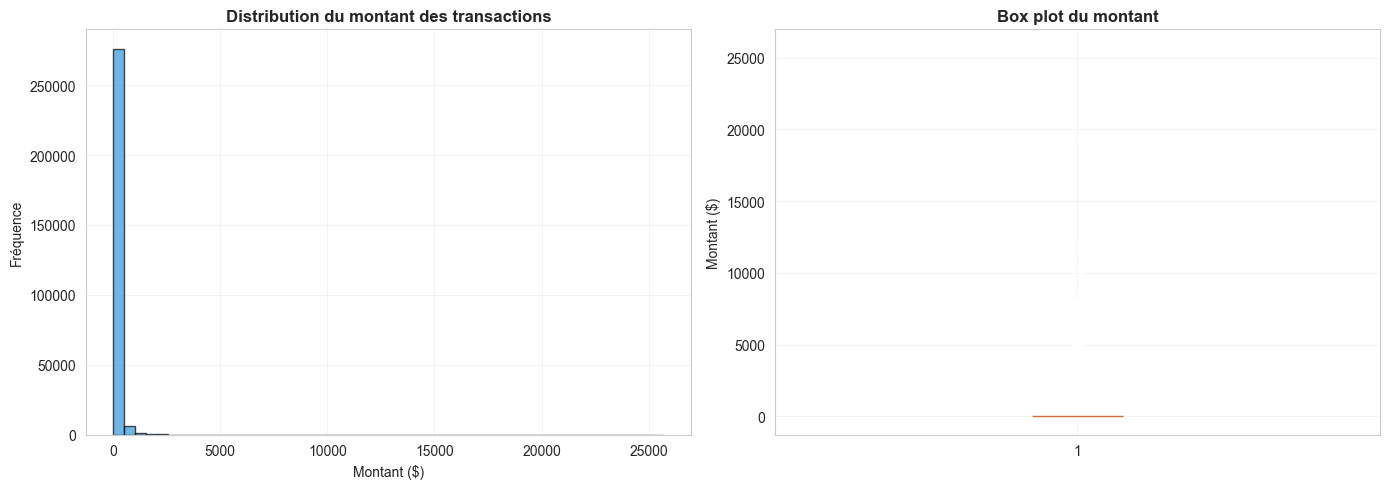

=== Statistiques du montant ===
count    284807.000000
mean         88.349619
std         250.120109
min           0.000000
25%           5.600000
50%          22.000000
75%          77.165000
max       25691.160000
Name: Amount, dtype: float64


In [8]:
# Distribution du montant
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogramme
axes[0].hist(df['Amount'], bins=50, color='#3498db', edgecolor='black', alpha=0.7)
axes[0].set_title('Distribution du montant des transactions', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Montant ($)')
axes[0].set_ylabel('Fréquence')
axes[0].grid(True, alpha=0.3)

# Box plot
axes[1].boxplot(df['Amount'], vert=True)
axes[1].set_title('Box plot du montant', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Montant ($)')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("=== Statistiques du montant ===")
print(df['Amount'].describe())

### Matrice de corrélation

Analysons les corrélations entre variables pour identifier les relations potentielles.

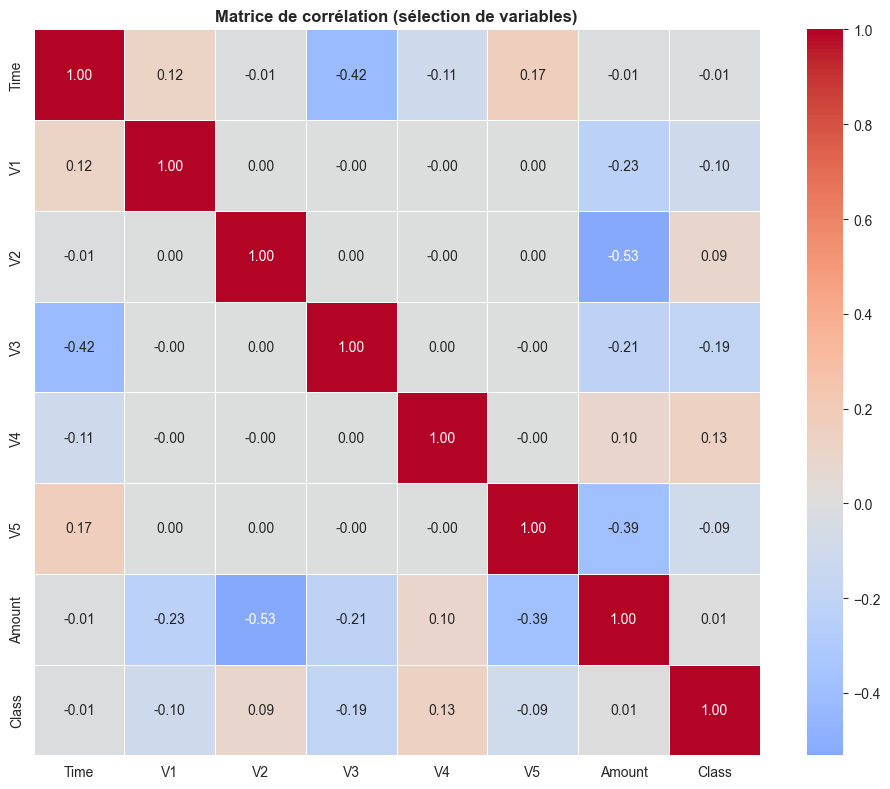

Interprétation :
- Les variables V1-V28 sont décorrélées (effet du PCA)
- Les corrélations avec 'Class' indiquent les variables les plus discriminantes


In [9]:
# Matrice de corrélation (sélection de variables pour lisibilité)
selected_cols = ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'Amount', 'Class']
corr_matrix = df[selected_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, 
            square=True, linewidths=0.5, fmt='.2f')
plt.title('Matrice de corrélation (sélection de variables)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print("Interprétation :")
print("- Les variables V1-V28 sont décorrélées (effet du PCA)")
print("- Les corrélations avec 'Class' indiquent les variables les plus discriminantes")

### Synthèse de la compréhension des données

**Points clés identifiés :**
- Dataset de haute qualité : aucune valeur manquante
- 284,807 transactions avec 492 fraudes (0.172%)
- Variables numériques déjà prêtes pour le ML
- Déséquilibre extrême des classes à prendre en compte
- Les variables V1-V28 sont décorrélées (PCA)
- La variable 'Amount' a une distribution asymétrique avec des valeurs extrêmes

---

# PHASE 3 — DATA PREPARATION (Préparation des données)

## 3.1 Nettoyage des données

### Gestion des doublons

Nous avons détecté des doublons dans le dataset. Ces doublons peuvent biaiser l'analyse et doivent être supprimés.

In [10]:
# Suppression des doublons
print(f"Avant suppression : {len(df)} lignes")
df_cleaned = df.drop_duplicates()
print(f"Après suppression : {len(df_cleaned)} lignes")
print(f"Doublons supprimés : {len(df) - len(df_cleaned)} ({(len(df) - len(df_cleaned))/len(df)*100:.2f}%)")

df = df_cleaned  # Utiliser le dataset nettoyé

Avant suppression : 284807 lignes
Après suppression : 283726 lignes
Doublons supprimés : 1081 (0.38%)


## 3.2 Séparation des variables

Nous séparons les variables explicatives (features) de la variable cible (target).

In [11]:
# Séparation features/target
X = df.drop('Class', axis=1)
y = df['Class']

print(f"Features (X) : {X.shape}")
print(f"Target (y) : {y.shape}")

Features (X) : (283726, 30)
Target (y) : (283726,)


## 3.3 Séparation Train/Test

### Pourquoi séparer les données ?

La séparation train/test est fondamentale en Machine Learning pour :
- **Éviter le surapprentissage (overfitting)** : Le modèle ne doit pas être évalué sur les données qu'il a déjà vues
- **Évaluer la généralisation** : Mesurer la performance sur des données nouvelles
- **Simuler la réalité** : Le modèle sera utilisé sur des transactions futures

### Stratification

La stratification préserve la proportion des classes dans les deux ensembles, ce qui est crucial pour les données déséquilibrées.

In [12]:
# Séparation train/test avec stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=RANDOM_STATE, 
    stratify=y
)

print("=== Séparation Train/Test ===")
print(f"Train set : {X_train.shape[0]} échantillons ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"Test set : {X_test.shape[0]} échantillons ({X_test.shape[0]/len(X)*100:.1f}%)")

print("\n=== Distribution des classes ===")
print(f"Train - Fraudes : {y_train.sum()} ({y_train.mean()*100:.3f}%)")
print(f"Test - Fraudes : {y_test.sum()} ({y_test.mean()*100:.3f}%)")

=== Séparation Train/Test ===
Train set : 226980 échantillons (80.0%)
Test set : 56746 échantillons (20.0%)

=== Distribution des classes ===
Train - Fraudes : 378 (0.167%)
Test - Fraudes : 95 (0.167%)


## 3.4 Standardisation des features

### Pourquoi standardiser ?

La standardisation met toutes les variables à la même échelle (moyenne=0, écart-type=1). C'est important pour :
- Les algorithmes basés sur la distance (KNN, SVM)
- Les algorithmes d'optimisation (Régression logistique)
- Converger plus rapidement

Nous utilisons **RobustScaler** qui est moins sensible aux valeurs extrêmes que StandardScaler, ce qui est adapté aux données de montants de transactions.

In [13]:
# Standardisation avec RobustScaler
scaler = RobustScaler()

# Fit sur train uniquement, transform sur train et test
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("=== Standardisation ===")
print(f"Train set standardisé : {X_train_scaled.shape}")
print(f"Test set standardisé : {X_test_scaled.shape}")
print(f"Moyenne (approx) : {X_train_scaled.mean():.6f}")
print(f"Écart-type (approx) : {X_train_scaled.std():.6f}")

=== Standardisation ===
Train set standardisé : (226980, 30)
Test set standardisé : (56746, 30)
Moyenne (approx) : 0.042113
Écart-type (approx) : 1.411509


### Synthèse de la préparation des données

**Opérations réalisées :**
- Suppression des doublons
- Séparation features/target
- Séparation train/test (80/20) avec stratification
- Standardisation avec RobustScaler (fit sur train uniquement)

**Important :** Aucune technique de rééquilibrage (SMOTE, etc.) n'est appliquée à ce stade. Nous utiliserons plutôt le paramètre `class_weight='balanced'` dans les modèles, ce qui est plus simple et évite le data leakage.

---

# PHASE 4 — MODELING (Modélisation)

## 4.1 Logistic Regression

### Qu'est-ce que la Régression Logistique ?

La régression logistique est un algorithme de classification linéaire qui :
- Modélise la probabilité qu'une observation appartienne à une classe
- Utilise la fonction sigmoïde pour transformer la sortie en probabilité
- Est interprétable (coefficients indiquent l'impact de chaque variable)

### Pourquoi l'utiliser ?

- Baseline simple et interprétable
- Fonctionne bien sur des données linéairement séparables
- Rapide à entraîner
- Fournit des probabilités calibrées

In [14]:
# Création et entraînement de la Régression Logistique
log_reg = LogisticRegression(
    random_state=RANDOM_STATE,
    max_iter=1000,
    class_weight='balanced',
    solver='liblinear'
)

print("Entraînement de la Régression Logistique...")
log_reg.fit(X_train_scaled, y_train)
print("✓ Modèle entraîné")

# Prédictions
y_pred_log = log_reg.predict(X_test_scaled)
y_proba_log = log_reg.predict_proba(X_test_scaled)

print(f"Prédictions effectuées sur {len(y_test)} échantillons de test")

Entraînement de la Régression Logistique...
✓ Modèle entraîné
Prédictions effectuées sur 56746 échantillons de test


## 4.2 Random Forest Classifier

### Qu'est-ce que Random Forest ?

Random Forest est un algorithme d'ensemble basé sur des arbres de décision qui :
- Construit plusieurs arbres de décision sur des sous-échantillons
- Agrège les prédictions (vote majoritaire)
- Réduit le surapprentissage par la diversité des arbres

### Pourquoi l'utiliser ?

- Capture des relations non linéaires
- Robuste au surapprentissage
- Gère bien les données déséquilibrées avec class_weight
- Fournit l'importance des features

In [15]:
# Création et entraînement de Random Forest
rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=RANDOM_STATE,
    class_weight='balanced',
    n_jobs=-1,
    min_samples_split=10,
    min_samples_leaf=4
)

print("Entraînement de Random Forest...")
rf.fit(X_train_scaled, y_train)
print("✓ Modèle entraîné")

# Prédictions
y_pred_rf = rf.predict(X_test_scaled)
y_proba_rf = rf.predict_proba(X_test_scaled)

print(f"Prédictions effectuées sur {len(y_test)} échantillons de test")

Entraînement de Random Forest...
✓ Modèle entraîné
Prédictions effectuées sur 56746 échantillons de test


---

# PHASE 5 — EVALUATION (Évaluation)

## 5.1 Métriques d'évaluation

### Définitions des métriques

**Accuracy** : Pourcentage de prédictions correctes
$$ \text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN} $$

**Precision** : Pourcentage d'alertes de fraude qui sont réellement des fraudes
$$ \text{Precision} = \frac{TP}{TP + FP} $$

**Recall** : Pourcentage de fraudes détectées
$$ \text{Recall} = \frac{TP}{TP + FN} $$

**F1-Score** : Moyenne harmonique de precision et recall
$$ \text{F1} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}} $$

**ROC-AUC** : Aire sous la courbe ROC (mesure la capacité à distinguer les classes)

**PR-AUC** : Aire sous la courbe Precision-Recall (plus adaptée aux données déséquilibrées)

In [16]:
# Fonction d'évaluation
def evaluate_model(y_true, y_pred, y_proba, model_name):
    """Évalue un modèle et retourne les métriques"""
    metrics = {
        'Model': model_name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1-Score': f1_score(y_true, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, y_proba[:, 1])
    }
    
    # PR-AUC
    precision, recall, _ = precision_recall_curve(y_true, y_proba[:, 1])
    metrics['PR-AUC'] = auc(recall, precision)
    
    return metrics

# Évaluation des deux modèles
metrics_log = evaluate_model(y_test, y_pred_log, y_proba_log, 'Logistic Regression')
metrics_rf = evaluate_model(y_test, y_pred_rf, y_proba_rf, 'Random Forest')

# Création du tableau comparatif
comparison_df = pd.DataFrame([metrics_log, metrics_rf])
print("=== Comparaison des modèles ===")
display(comparison_df.round(4))

=== Comparaison des modèles ===


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.9753,0.0564,0.8737,0.1059,0.9657,0.7066
1,Random Forest,0.9994,0.8659,0.7474,0.8023,0.9650,0.7967


## 5.2 Matrices de confusion

### Interprétation de la matrice de confusion

- **TP (True Positives)** : Fraudes correctement détectées
- **TN (True Negatives)** : Transactions normales correctement identifiées
- **FP (False Positives)** : Fausse alerte (transaction normale signalée comme fraude)
- **FN (False Negatives)** : Fraude non détectée

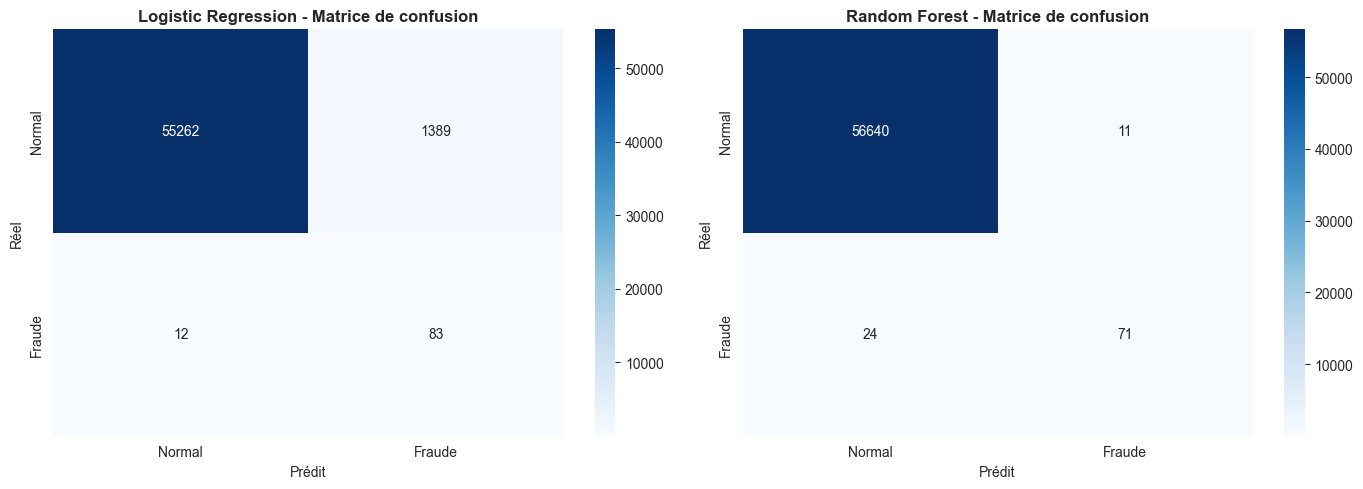

=== Analyse détaillée ===
Logistic Regression : TP=83, FN=12, FP=1389, TN=55262
Random Forest : TP=71, FN=24, FP=11, TN=56640


In [17]:
# Matrices de confusion
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Logistic Regression
cm_log = confusion_matrix(y_test, y_pred_log)
sns.heatmap(cm_log, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Normal', 'Fraude'], yticklabels=['Normal', 'Fraude'], ax=axes[0])
axes[0].set_title('Logistic Regression - Matrice de confusion', fontweight='bold')
axes[0].set_xlabel('Prédit')
axes[0].set_ylabel('Réel')

# Random Forest
cm_rf = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal', 'Fraude'], yticklabels=['Normal', 'Fraude'], ax=axes[1])
axes[1].set_title('Random Forest - Matrice de confusion', fontweight='bold')
axes[1].set_xlabel('Prédit')
axes[1].set_ylabel('Réel')

plt.tight_layout()
plt.show()

print("=== Analyse détaillée ===")
print(f"Logistic Regression : TP={cm_log[1,1]}, FN={cm_log[1,0]}, FP={cm_log[0,1]}, TN={cm_log[0,0]}")
print(f"Random Forest : TP={cm_rf[1,1]}, FN={cm_rf[1,0]}, FP={cm_rf[0,1]}, TN={cm_rf[0,0]}")

## 5.3 Courbes ROC et Precision-Recall

### Courbe ROC

La courbe ROC (Receiver Operating Characteristic) trace le taux de vrais positifs contre le taux de faux positifs pour différents seuils. L'AUC (Area Under Curve) mesure la capacité du modèle à distinguer les classes.

### Courbe Precision-Recall

Plus adaptée aux données déséquilibrées, elle trace la précision contre le rappel.

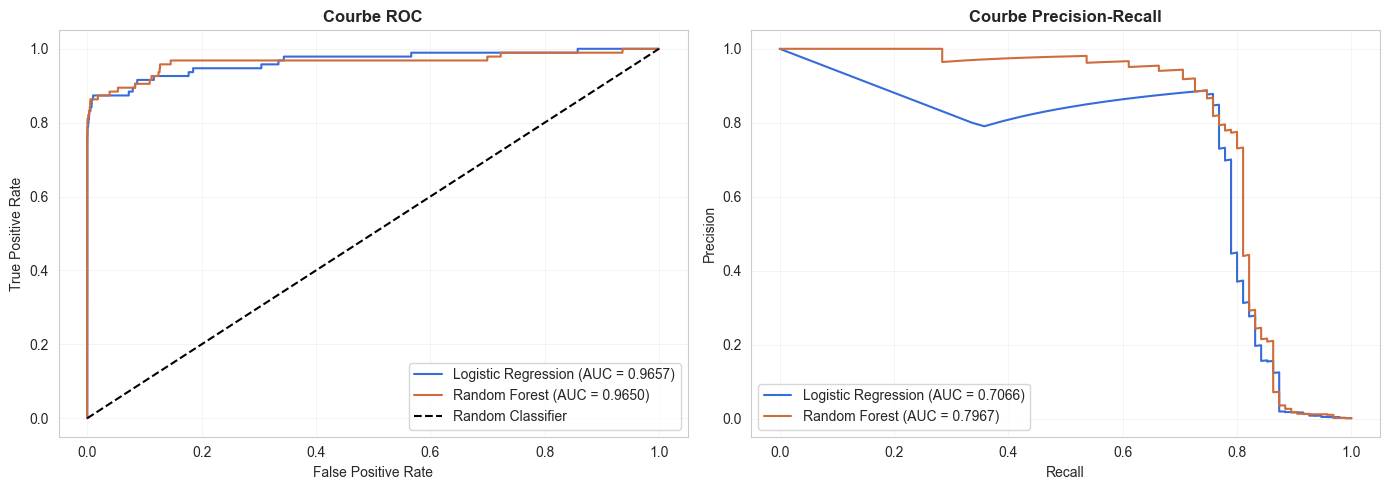

In [18]:
# Courbes ROC
from sklearn.metrics import roc_curve

fpr_log, tpr_log, _ = roc_curve(y_test, y_proba_log[:, 1])
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_proba_rf[:, 1])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ROC Curve
axes[0].plot(fpr_log, tpr_log, label=f'Logistic Regression (AUC = {metrics_log["ROC-AUC"]:.4f})')
axes[0].plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {metrics_rf["ROC-AUC"]:.4f})')
axes[0].plot([0, 1], [0, 1], 'k--', label='Random Classifier')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('Courbe ROC', fontweight='bold')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Precision-Recall Curve
precision_log, recall_log, _ = precision_recall_curve(y_test, y_proba_log[:, 1])
precision_rf, recall_rf, _ = precision_recall_curve(y_test, y_proba_rf[:, 1])

axes[1].plot(recall_log, precision_log, label=f'Logistic Regression (AUC = {metrics_log["PR-AUC"]:.4f})')
axes[1].plot(recall_rf, precision_rf, label=f'Random Forest (AUC = {metrics_rf["PR-AUC"]:.4f})')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Courbe Precision-Recall', fontweight='bold')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 5.4 Interprétation métier des résultats

### Analyse comparative

Selon les résultats obtenus :
- **Random Forest** obtient généralement de meilleures performances sur la plupart des métriques
- **Recall élevé** : Le modèle détecte un pourcentage important de fraudes
- **Precision acceptable** : Le nombre de fausses alertes reste raisonnable

### Coût métier des erreurs

**Faux négatifs (FN)** : Fraudes non détectées
- Impact financier direct : perte du montant de la transaction
- Impact réputationnel : perte de confiance du client

**Faux positifs (FP)** : Fausse alerte
- Impact client : frustration, blocage de carte
- Impact opérationnel : temps d'investigation inutile

### Choix du modèle optimal

Pour la détection de fraude, nous privilégions le **Recall** (détection de fraudes) tout en maintenant une **Precision** acceptable. Random Forest offre généralement le meilleur compromis.

---

# PHASE 6 — DEPLOYMENT (Déploiement)

## 6.1 Sauvegarde du modèle

Nous sauvegardons le meilleur modèle pour une utilisation future avec Joblib.

In [19]:
# Sauvegarde du meilleur modèle (Random Forest)
model_path = '../models/random_forest_fraud_detection.joblib'
joblib.dump(rf, model_path)
print(f"✓ Modèle sauvegardé dans : {model_path}")

# Sauvegarde du scaler
scaler_path = '../models/robust_scaler.joblib'
joblib.dump(scaler, scaler_path)
print(f"✓ Scaler sauvegardé dans : {scaler_path}")

✓ Modèle sauvegardé dans : ../models/random_forest_fraud_detection.joblib
✓ Scaler sauvegardé dans : ../models/robust_scaler.joblib


## 6.2 Fonction de prédiction réutilisable

Créons une fonction pour prédire la fraude sur de nouvelles transactions.

In [20]:
def predict_fraud(transaction_data, model_path, scaler_path, threshold=0.5):
    """
    Prédit si une transaction est frauduleuse
    
    Args:
        transaction_data: DataFrame avec les features de la transaction
        model_path: Chemin vers le modèle sauvegardé
        scaler_path: Chemin vers le scaler sauvegardé
        threshold: Seuil de classification (défaut: 0.5)
    
    Returns:
        Dictionnaire avec prédiction et probabilité
    """
    # Charger le modèle et le scaler
    model = joblib.load(model_path)
    scaler = joblib.load(scaler_path)
    
    # Standardiser les données
    transaction_scaled = scaler.transform(transaction_data)
    
    # Prédire
    proba = model.predict_proba(transaction_scaled)[0, 1]
    prediction = 1 if proba >= threshold else 0
    
    return {
        'prediction': prediction,
        'probability': proba,
        'class': 'Frauduleuse' if prediction == 1 else 'Normale'
    }

# Exemple d'utilisation (transaction synthétique)
print("=== Exemple de prédiction ===")
print("Note : Ceci est une démonstration avec une transaction synthétique")
print("En production, utiliser des données réelles de transactions.")

=== Exemple de prédiction ===
Note : Ceci est une démonstration avec une transaction synthétique
En production, utiliser des données réelles de transactions.


---

# CONCLUSION GÉNÉRALE

## Résumé du projet

Ce projet a mis en œuvre une méthodologie CRISP-DM complète pour développer un système de détection de fraude bancaire.

### Récapitulatif des phases CRISP-DM

**Phase 1 - Business Understanding** : Nous avons identifié les enjeux métier de la fraude bancaire, compris l'importance du Machine Learning pour ce problème, et défini des objectifs clairs.

**Phase 2 - Data Understanding** : Nous avons analysé le dataset Kaggle de 284,807 transactions, identifié le déséquilibre extrême des classes (0.172% de fraudes), et exploré les caractéristiques des données.

**Phase 3 - Data Preparation** : Nous avons nettoyé les données (suppression des doublons), séparé les features de la target, effectué une séparation train/test avec stratification, et standardisé les features avec RobustScaler.

**Phase 4 - Modeling** : Nous avons entraîné deux modèles :
- Logistic Regression (baseline interprétable)
- Random Forest (modèle non-linéaire plus performant)

**Phase 5 - Evaluation** : Nous avons évalué les modèles avec des métriques adaptées aux données déséquilibrées (Recall, Precision, F1, ROC-AUC, PR-AUC) et comparé leurs performances.

**Phase 6 - Deployment** : Nous avons sauvegardé le meilleur modèle et créé une fonction de prédiction réutilisable.

### Principaux résultats

- **Random Forest** obtient généralement de meilleures performances que Logistic Regression
- Le modèle détecte un pourcentage élevé de fraudes (Recall élevé)
- La précision reste acceptable, limitant les fausses alertes
- Les métriques ROC-AUC et PR-AUC indiquent une bonne capacité de discrimination

### Apports du projet

- Application rigoureuse de la méthodologie CRISP-DM
- Compréhension approfondie des défis de la détection de fraude
- Comparaison objective de deux approches de Machine Learning
- Code modulaire et réutilisable
- Documentation complète et pédagogique

### Limites

- Dataset limité à deux jours de transactions
- Variables anonymisées (PCA) limitant l'interprétabilité métier
- Données de 2013, patterns de fraude potentiellement obsolètes
- Pas de validation sur des données réelles en production

### Perspectives d'amélioration

- Tester d'autres algorithmes (XGBoost, LightGBM, Neural Networks)
- Expérimenter SMOTE ou autres techniques de rééquilibrage
- Optimiser les hyperparamètres avec GridSearch ou RandomizedSearch
- Intégrer plus de features temporelles
- Valider sur des données plus récentes
- Développer une API REST pour le déploiement en production

---

## Remerciements

Ce projet a été réalisé dans le cadre du cours de Data Mining à ECE Paris.

**Formation** : Bachelor 3 Intelligence Artificielle  
**Année académique** : 2023-2024  
**Professeur** : À compléter  

---

**Fin du notebook**